# Appendix E | Worked solutions

*Convolution and Parallel Scans*

An impulse exposes kernel order and wraparound. Composing affine maps exposes the difference between regrouping and reordering. Each efficient calculation is compared with a simple reference whose indexing is visible.

Eight exercises progress from tracing small calculations to diagnosing implementation errors. These are controlled numerical examples, not performance or model-quality benchmarks.

## Setup

Run all cells in order from anywhere inside the companion repository. The written PDF contains every problem, explanation, and plot; the notebook PDF adds the code and saved outputs. NumPy and Matplotlib are required; Appendix C also uses PyTorch. No downloads, credentials, GPU, or trained checkpoint are needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch04_attention/attention.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
from examples.ch13_state_spaces.model import causal_convolution, fft_causal_convolution
from examples.ch14_selective_ssm.model import compose_diagonal


## 1. Keep the kernel order

**Problem.** For inputs $(3,1,-2)$ and lag coefficients $(2,-1)$, compute causal outputs. Give weights for an oldest-to-newest cross-correlation window with left padding.

**Solution.** The outputs are $y_1=2(3)-1(0)=6$, $y_2=2(1)-1(3)=-1$, and $y_3=2(-2)-1(1)=-5$. In an oldest-to-newest window, the previous input appears first, so the weights must be $(-1,2)$. Pad one zero to the left. Both conventions represent the same causal operator only after matching their ordering.

In [2]:
x=np.array([3.,1.,-2.]);kernel=np.array([2.,-1.])
y=causal_convolution(x,kernel)
padded=np.pad(x,(1,0))
chronological=np.array([padded[t:t+2]@kernel[::-1] for t in range(3)])
np.testing.assert_array_equal(y,[6,-1,-5])
np.testing.assert_array_equal(chronological,y)
print("Lag-ordered convolution:",y)
print("Chronological weights:",kernel[::-1],"Result:",chronological)

Lag-ordered convolution: [ 6. -1. -5.]
Chronological weights: [-1.  2.] Result: [ 6. -1. -5.]


## 2. Retain the initial state

**Problem.** For $h_t=h_{t-1}/2+x_t$, initial state 6, and inputs $(0,2,1)$, find the final state by stepping and unrolling. Separate initial-state and input contributions.

**Solution.** Stepping gives $h_1=3$, $h_2=3.5$, and $h_3=2.75$. Unrolling gives $(1/2)^3(6)+(1/2)^2(0)+(1/2)(2)+1=0.75+2=2.75$. A convolution of the inputs alone returns 2 at the final position, so omitting the initial-state term would miss 0.75. Nonzero initialization is a useful test because a zero-only fixture hides that error.

In [3]:
x=np.array([0.,2.,1.]);a=.5;h0=6.
h=h0;states=[]
for value in x:
    h=a*h+value;states.append(h)
initial=a**len(x)*h0
inputs=sum(a**(len(x)-1-j)*v for j,v in enumerate(x))
assert h==2.75 and initial==.75 and inputs==2
np.testing.assert_array_equal(states,[3,3.5,2.75])
print("States:",states,"Final initial/input contributions:",initial,inputs)

States: [np.float64(3.0), np.float64(3.5), np.float64(2.75)] Final initial/input contributions: 0.75 2.0


## 3. Understand a reset map

**Problem.** Compose $(1/2,2)$ followed by $(0,5)$ and then reverse their order. Explain what happens to the incoming state and first write.

**Solution.** In time order, the second map multiplies the entire previous state by zero and writes 5. The composition is $(0\cdot1/2,0\cdot2+5)=(0,5)$. It erases both the incoming state and the first write. In reverse order, the reset writes 5 and the other map then gives $(1/2)(5)+2=4.5$, so the composition is $(0,4.5)$. Both erase the original state, but they preserve different later writes. Associativity does not permit swapping them.

In [4]:
first=(np.array([.5]),np.array([2.]))
reset=(np.array([0.]),np.array([5.]))
forward=compose_diagonal(first,reset)
reverse=compose_diagonal(reset,first)
np.testing.assert_array_equal(np.concatenate(forward),[0,5])
np.testing.assert_array_equal(np.concatenate(reverse),[0,4.5])
print("First then reset:",tuple(v.item() for v in forward))
print("Reset then first:",tuple(v.item() for v in reverse))

First then reset: (0.0, 5.0)
Reset then first: (0.0, 4.5)


## 4. Prevent circular wraparound

**Problem.** Run the direct and padded-FFT helpers on input $(0,0,1)$ and kernel $(1,2,3)$. Compare their three outputs, and explain what wraps if the FFT length is three.

**Solution.** The full linear convolution is $(0,0,1,2,3)$. Both canonical functions keep its first three entries, giving $(0,0,1)$ within floating-point tolerance. A three-point FFT performs circular convolution: full output position 4 wraps into position 1 and position 5 into position 2. It gives $(2,3,1)$, incorrectly making earlier outputs depend on the last input. Padding to at least $n+K-1=5$ prevents the overlap. An absolute tolerance is needed for expected zeros after an FFT.

Full linear: [0. 0. 1. 2. 3.] Causal prefix: [0. 0. 1.]
Incorrect three-point FFT: [2. 3. 1.]


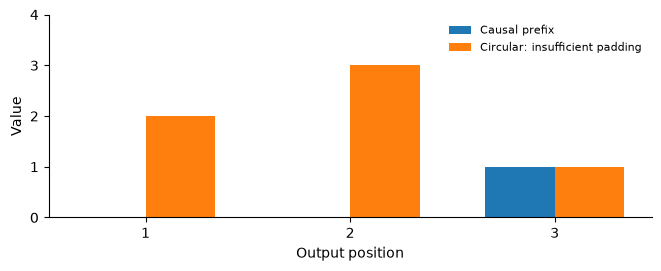

In [5]:
x=np.array([0.,0.,1.]);kernel=np.array([1.,2.,3.])
direct=causal_convolution(x,kernel);padded=fft_causal_convolution(x,kernel)
full=np.convolve(x,kernel)
circular=np.fft.irfft(np.fft.rfft(x)*np.fft.rfft(kernel),n=3)
np.testing.assert_allclose(direct,[0,0,1],atol=1e-12)
np.testing.assert_allclose(padded,direct,atol=1e-12)
np.testing.assert_allclose(circular,[2,3,1],atol=1e-12)
print("Full linear:",full,"Causal prefix:",padded)
print("Incorrect three-point FFT:",circular)
fig,ax=plt.subplots(figsize=(6.5,2.6),layout="constrained")
positions=np.arange(1,4)
ax.bar(positions-.17,direct,width=.34,label="Causal prefix")
ax.bar(positions+.17,circular,width=.34,label="Circular: insufficient padding")
ax.set(xticks=positions,xlabel="Output position",ylabel="Value",ylim=(0,4))
ax.legend(frameon=False,fontsize=8);plt.show()

## 5. Build an independent causal reference

**Problem.** Use the lower-triangular Toeplitz matrix with diagonal 2 and first subdiagonal $-1$ on $(3,1,-2)$. Replace only the final input by 100. Which outputs may change? Check the padded FFT too.

**Solution.** The matrix product reproduces $(6,-1,-5)$. Changing the third input cannot affect the first two outputs because their matrix rows have a zero in the third column. The last output becomes $2(100)-1(1)=199$. The matrix and padded FFT agree. This perturbation test checks information flow independently of one fixed expected result.

In [6]:
operator=np.array([[2.,0.,0.],[-1.,2.,0.],[0.,-1.,2.]])
x=np.array([3.,1.,-2.]);changed=x.copy();changed[-1]=100
base=operator@x;after=operator@changed
np.testing.assert_array_equal(base,[6,-1,-5])
np.testing.assert_array_equal(after,[6,-1,199])
np.testing.assert_allclose(fft_causal_convolution(changed,[2,-1]),after,atol=1e-12)
np.testing.assert_allclose(fft_causal_convolution(x,[2,-1])[:2],
                           fft_causal_convolution(changed,[2,-1])[:2],atol=1e-12)
print("Original outputs:",base,"After changing only the last input:",after)

Original outputs: [ 6. -1. -5.] After changing only the last input: [  6.  -1. 199.]


## 6. Verify every prefix

**Problem.** Use maps $(1/2,2)$, $(1/4,-1)$, $(3/4,1)$ and initial state 4. Check all inclusive prefixes with `compose_diagonal`, both final parenthesizations, and reversed time order.

**Solution.** The inclusive maps are $(1/2,2)$, $(1/8,-1/2)$, and $(3/32,5/8)$. Applying each to 4 gives states $(4,0,1)$, which agree with sequential updates. Both valid parenthesizations give the same final map. Reversing the time order gives final state 2, because each later map transforms earlier writes differently. The code checks every prefix; checking only the final state could miss an error in returned intermediate states.

Prefix maps: [(0.5, 2.0), (0.125, -0.5), (0.09375, 0.625)]
States: [4.0, 0.0, 1.0] Reversed-order final state: 2.0


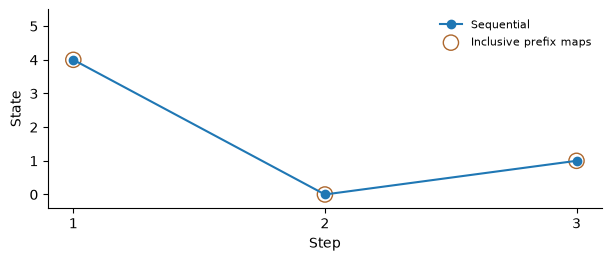

In [7]:
maps=[(np.array([a]),np.array([r])) for a,r in [(.5,2),(.25,-1),(.75,1)]]
prefix=(np.ones(1),np.zeros(1));prefixes=[];states=[];h=np.array([4.])
for current in maps:
    prefix=compose_diagonal(prefix,current);prefixes.append(prefix)
    h=current[0]*h+current[1];states.append(h.item())
from_prefix=[(a*4+r).item() for a,r in prefixes]
np.testing.assert_array_equal(states,[4,0,1])
np.testing.assert_array_equal(from_prefix,states)
left=compose_diagonal(compose_diagonal(maps[0],maps[1]),maps[2])
right=compose_diagonal(maps[0],compose_diagonal(maps[1],maps[2]))
np.testing.assert_array_equal(np.concatenate(left),np.concatenate(right))
h=np.array([4.])
for a,r in reversed(maps): h=a*h+r
assert h.item()==2
print("Prefix maps:",[(a.item(),r.item()) for a,r in prefixes])
print("States:",states,"Reversed-order final state:",h.item())
fig,ax=plt.subplots(figsize=(6,2.5),layout="constrained")
ax.plot([1,2,3],states,"o-",label="Sequential")
ax.scatter([1,2,3],from_prefix,facecolors="none",edgecolors="#ad672d",
           s=120,label="Inclusive prefix maps")
ax.set(xticks=[1,2,3],xlabel="Step",ylabel="State",ylim=(-.4,5.5))
ax.legend(frameon=False,fontsize=8);plt.show()

## 7. Find the limit of a fixed kernel

**Problem.** Let $h_t=a_t h_{t-1}+x_t$, zero initial state, and retentions $(1/2,1/4,3/4)$. Compare impulses $(1,0,0)$ and $(0,1,0)$. Can one lag-one kernel coefficient represent both?

**Solution.** The first impulse gives states $(1,1/4,3/16)$; the second gives $(0,1,3/4)$. One step after the first impulse its coefficient is $a_2=1/4$; one step after the second it is $a_3=3/4$. A time-invariant convolution must assign the same coefficient to the same lag, so it cannot represent both responses. The varying-coefficient recurrence remains causal, and its affine updates can still be composed when their coefficients are already available.

In [8]:
retentions=np.array([.5,.25,.75])
def trace(inputs):
    h=0.;result=[]
    for a,x in zip(retentions,inputs):
        h=a*h+x;result.append(h)
    return np.array(result)
first=trace([1,0,0]);second=trace([0,1,0])
np.testing.assert_array_equal(first,[1,.25,.1875])
np.testing.assert_array_equal(second,[0,1,.75])
assert first[1]!=second[2]
print("First impulse:",first,"Second impulse:",second)
print("Lag-one coefficients:",first[1],second[2])

First impulse: [1.     0.25   0.1875] Second impulse: [0.   1.   0.75]
Lag-one coefficients: 0.25 0.75


## 8. Separate work, span, and rounding

**Problem.** For eight maps compare final-only tree reduction, standard upsweep/downsweep exclusive scan, and independently computed sequential prefixes. Reproduce the binary64 cancellation example and explain the numerical limit of associativity.

**Solution.** A balanced final-only reduction uses seven combinations and three dependent levels. The standard exclusive scan uses seven up and seven down: 14 combinations and six dependent levels; its outputs are the identity, then the first map, then the first two, through the first seven. Converting to inclusive outputs adds at most eight parallel combinations and one level. Independently computing every inclusive prefix needs $0+1+\cdots+7=28$ combinations; if the eight chains run concurrently, their longest dependency chain is seven. These count fixed-cost maps and sufficient parallel resources, not measured execution time. In binary64, $(10^{16}-10^{16})+1=1$, but $10^{16}+(-10^{16}+1)=0$ because the inner addition loses the unit. Regrouping preserves exact real algebra while potentially changing rounding; compare implementations with explicit numerical tolerances.

In [9]:
n=8
reduction_work=n-1;reduction_span=int(np.log2(n))
scan_work=2*(n-1);scan_span=2*int(np.log2(n))
independent_work=sum(range(n));independent_span=n-1
assert (reduction_work,reduction_span)==(7,3)
assert (scan_work,scan_span)==(14,6)
assert (independent_work,independent_span)==(28,7)
a=np.float64(1e16);b=np.float64(-1e16);c=np.float64(1)
left=(a+b)+c;right=a+(b+c)
assert left==1 and right==0
print("Reduction work/span:",reduction_work,reduction_span)
print("Exclusive scan work/span:",scan_work,scan_span)
print("Independent prefixes work/span:",independent_work,independent_span)
print("Different binary64 groupings:",left,right)

Reduction work/span: 7 3
Exclusive scan work/span: 14 6
Independent prefixes work/span: 28 7
Different binary64 groupings: 1.0 0.0
